## Robust curve challenge

Submission: `submission_branchA.csv` (`idx`, `y_hat`) for all holdout rows — Huber robust regression on B-spline features with CV-tuned knots (see code cells).

train (200, 3) holdout (480, 2)
t ranges — train: 0.029749274 2.919673016 hold: 0.02 2.92
hold points outside train t span: 3
median |dy/dt|: 13.815747487781666
saved C:\Users\goela\Projects\LLM_Jupyter\demos\benchmark_robust_curve\_explore_train.png


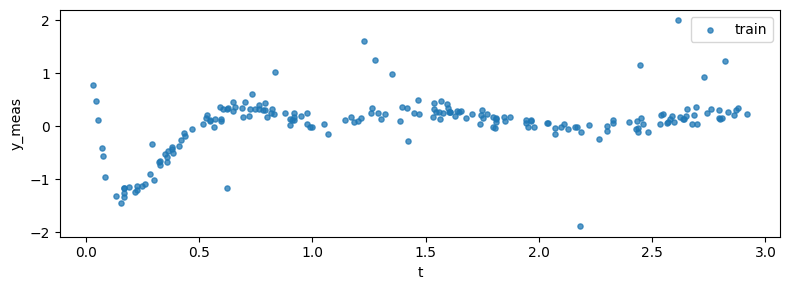

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path("benchmarks/case_studies/benchmark_robust_curve")
tr = pd.read_csv(root / "train.csv")
ho = pd.read_csv(root / "holdout_inputs.csv")
print("train", tr.shape, "holdout", ho.shape)
print("t ranges — train:", float(tr.t.min()), float(tr.t.max()), "hold:", float(ho.t.min()), float(ho.t.max()))
print("hold points outside train t span:", int((ho.t < tr.t.min()).sum() + (ho.t > tr.t.max()).sum()))
# residual roughness vs local linear trend
tr = tr.sort_values("t")
dy = np.diff(tr.y_meas.values)
dt = np.diff(tr.t.values)
print("median |dy/dt|:", float(np.median(np.abs(dy / (dt + 1e-12)))))

fig, ax = plt.subplots(figsize=(8, 3))
ax.scatter(tr.t, tr.y_meas, s=14, alpha=0.75, c="tab:blue", label="train")
ax.set_xlabel("t")
ax.set_ylabel("y_meas")
ax.legend()
fig.tight_layout()
fig.savefig(root / "_explore_train.png", dpi=130)
print("saved", root.resolve() / "_explore_train.png")

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import HuberRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer

root = Path("benchmarks/case_studies/benchmark_robust_curve")
tr = pd.read_csv(root / "train.csv")
ho = pd.read_csv(root / "holdout_inputs.csv")

X = tr[["t"]].values
y = tr.y_meas.values.astype(float)
X_ho = ho[["t"]].values.astype(float)


class SplineFourierFeatures(BaseEstimator, TransformerMixin):
    """Quantile B-splines (linear extrapolation) + low-order Fourier on train-span-scaled phase."""

    def __init__(self, n_knots=18, degree=3, n_harmonics=0, knots="quantile"):
        self.n_knots = n_knots
        self.degree = degree
        self.n_harmonics = n_harmonics
        self.knots = knots

    def fit(self, X, y=None):
        self.spl_ = SplineTransformer(
            n_knots=self.n_knots,
            degree=self.degree,
            include_bias=True,
            knots=self.knots,
            extrapolation="linear",
        )
        self.spl_.fit(X)
        self.t0_ = float(np.min(X))
        self.span_ = float(np.max(X) - self.t0_) + 1e-12
        return self

    def transform(self, X):
        F = self.spl_.transform(X)
        h = self.n_harmonics
        if h <= 0:
            return F
        t = X.ravel()
        phase = (t - self.t0_) / self.span_ * 2 * np.pi
        blocks = [F]
        for k in range(1, h + 1):
            blocks.append(np.sin(k * phase)[:, None])
            blocks.append(np.cos(k * phase)[:, None])
        return np.hstack(blocks)


pipe = Pipeline(
    [
        ("feat", SplineFourierFeatures()),
        ("hub", HuberRegressor(fit_intercept=True, max_iter=3000, tol=1e-6)),
    ]
)

param_grid = {
    "feat__n_knots": list(range(10, 34, 2)),
    "feat__knots": ["quantile", "uniform"],
    "feat__n_harmonics": [0, 3, 6, 9],
    "hub__epsilon": [1.1, 1.2, 1.35],
    "hub__alpha": [1e-6, 1e-4, 1e-3],
}
cv = KFold(n_splits=5, shuffle=True, random_state=0)
search = GridSearchCV(
    pipe,
    param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    refit=True,
    n_jobs=-1,
)
search.fit(X, y)
print("best_params", search.best_params_)
print("CV_RMSE (~neg_score):", float(-search.best_score_))

best = search.best_estimator_
y_hat = best.predict(X_ho)
out = pd.DataFrame({"idx": ho["idx"].astype(int), "y_hat": y_hat})
sub = root / "submission_branchA.csv"
out.to_csv(sub, float_format="%.10f", index=False)
assert len(out) == 480
print("wrote", sub.resolve(), "rows", len(out))

best_params {'feat__knots': 'quantile', 'feat__n_harmonics': 6, 'feat__n_knots': 12, 'hub__alpha': 1e-06, 'hub__epsilon': 1.1}
CV_RMSE (~neg_score): 0.28401213497786515
wrote C:\Users\goela\Projects\LLM_Jupyter\demos\benchmark_robust_curve\submission_branchA.csv rows 480
